In [1]:
import json
import polars as pl
import matplotlib.pyplot as plt

with open("../chicago-city.geojson", "r", encoding="utf-8") as file:
    geojson = json.load(file)

features = geojson["features"]

print("GeoJSON Type:", geojson["type"])
print("Number of Features:", len(features))

GeoJSON Type: FeatureCollection
Number of Features: 1


In [2]:
# Part 1

records = []

for i, feature in enumerate(features):
    geometry = feature.get("geometry")
    properties = feature.get("properties") or {}

    records.append({
        "feature_id": i,
        "geometry_type": geometry.get("type") if geometry else None,
        "properties_count": len(properties),
        "has_geometry": geometry is not None
    })

df = pl.DataFrame(records)

print("Dataset Shape:")
print(df.shape)

print("\nDataset Schema:")
df.glimpse()

print("\nMissing Values:")
print(df.null_count())

print("\nDescriptive Statistics:")
print(df.describe())

Dataset Shape:
(1, 4)

Dataset Schema:
Rows: 1
Columns: 4
$ feature_id        <i64> 0
$ geometry_type     <str> 'MultiPolygon'
$ properties_count  <i64> 0
$ has_geometry     <bool> True


Missing Values:
shape: (1, 4)
┌────────────┬───────────────┬──────────────────┬──────────────┐
│ feature_id ┆ geometry_type ┆ properties_count ┆ has_geometry │
│ ---        ┆ ---           ┆ ---              ┆ ---          │
│ u32        ┆ u32           ┆ u32              ┆ u32          │
╞════════════╪═══════════════╪══════════════════╪══════════════╡
│ 0          ┆ 0             ┆ 0                ┆ 0            │
└────────────┴───────────────┴──────────────────┴──────────────┘

Descriptive Statistics:
shape: (9, 5)
┌────────────┬────────────┬───────────────┬──────────────────┬──────────────┐
│ statistic  ┆ feature_id ┆ geometry_type ┆ properties_count ┆ has_geometry │
│ ---        ┆ ---        ┆ ---           ┆ ---              ┆ ---          │
│ str        ┆ f64        ┆ str           ┆ f64       

### Part 1: Dataset Profiling: Chicago City GeoJSON

The Chicago City GeoJSON dataset contains one geographic feature representing Chicago's city boundary. The geometry type is MultiPolygon, which means the boundary can consist of multiple polygons.

I converted the feature information into a Polars DataFrame with 1 row and 4 columns for profiling. The columns include feature ID, geometry type, property count, and whether geometry is available.

The profiling results showed no missing values in these four fields. The feature contains valid geometry information, but no additional properties.

Since this dataset represents a geographic boundary rather than individual observations, descriptive statistics such as mean and standard deviation are not very meaningful. The coordinates will be more useful for mapping and geographic comparisons.

This dataset can help identify Chicago's geographic boundaries when analyzing crime and camera locations.

In [3]:
# Part 2

print("Missing Geometry:")
print(sum(f.get("geometry") is None for f in features))

print("\nDuplicate Features:")
print(len(features) - len({
    json.dumps(f, sort_keys=True) for f in features
}))

rings = []
coordinates = []

for feature in features:
    geometry = feature.get("geometry")

    if geometry is None:
        continue

    if geometry["type"] == "MultiPolygon":
        polygons = geometry["coordinates"]
    elif geometry["type"] == "Polygon":
        polygons = [geometry["coordinates"]]
    else:
        print("Unsupported geometry:", geometry["type"])
        continue

    for polygon in polygons:
        for ring in polygon:
            rings.append(ring)

            for point in ring:
                coordinates.append(point)

print("\nTotal Coordinate Points:")
print(len(coordinates))

print("\nTotal Polygon Rings:")
print(len(rings))

invalid_coordinates = 0

for point in coordinates:
    longitude, latitude = point[:2]

    if not (-180 <= longitude <= 180 and
            -90 <= latitude <= 90):
        invalid_coordinates += 1

print("\nInvalid Coordinates:")
print(invalid_coordinates)

unclosed_rings = 0
short_rings = 0

for ring in rings:
    if len(ring) < 4:
        short_rings += 1

    if ring[0] != ring[-1]:
        unclosed_rings += 1

print("\nUnclosed Polygon Rings:")
print(unclosed_rings)

print("\nRings With Fewer Than Four Points:")
print(short_rings)

consecutive_duplicates = 0

for ring in rings:
    for i in range(1, len(ring)):
        if ring[i] == ring[i - 1]:
            consecutive_duplicates += 1

print("\nConsecutive Duplicate Points:")
print(consecutive_duplicates)

Missing Geometry:
0

Duplicate Features:
0

Total Coordinate Points:
12731

Total Polygon Rings:
5

Invalid Coordinates:
0

Unclosed Polygon Rings:
0

Rings With Fewer Than Four Points:
0

Consecutive Duplicate Points:
156


### Part 2: Anomaly Detection:Chicago City GeoJSON

I checked the Chicago City GeoJSON dataset for missing geometry, duplicate features, invalid coordinates, and problems with polygon boundaries.

The dataset contains 12,731 coordinate points across 5 polygon rings. There were no missing geometries, duplicate features, invalid coordinates, or unclosed polygon rings. All polygon rings also contained at least four points.

However, I found 156 consecutive duplicate coordinate points. These may be redundant vertices in the geographic boundary, but they do not necessarily make the geometry invalid.

I decided to leave these points unchanged and flag them rather than remove them, since modifying the coordinates could affect the original geographic boundary. No features or coordinate points were removed during this analysis.

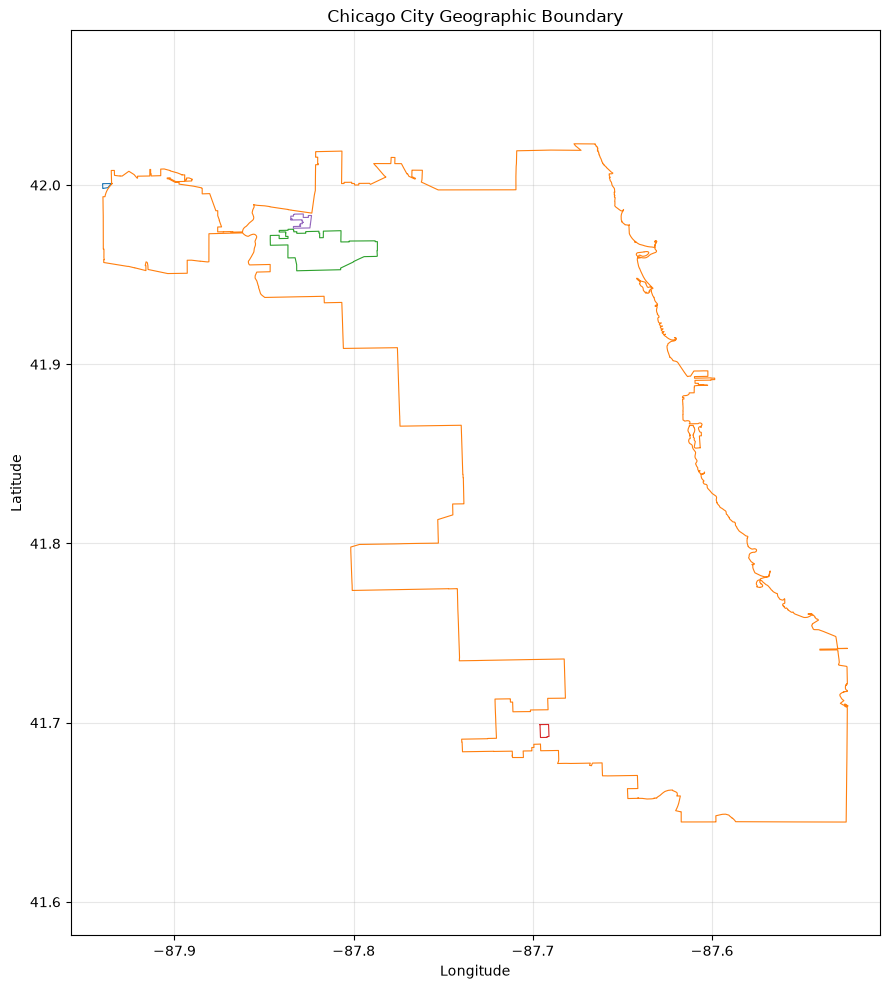

In [4]:
# Part 3: Geographic Visualization

plt.figure(figsize=(9, 10))

for ring in rings:
    longitudes = [point[0] for point in ring]
    latitudes = [point[1] for point in ring]

    plt.plot(
        longitudes,
        latitudes,
        linewidth=0.8
    )

plt.title("Chicago City Geographic Boundary")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.axis("equal")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Part 3: Geographic Visualization: Chicago City

The plot shows Chicago's geographic boundary using latitude and longitude coordinates. The smaller shapes represent additional polygon areas in the dataset.

This map helps us understand Chicago's geographic coverage and can be useful for analyzing crime and Flock camera locations.